# Brooklyn Community Board Budget Requests: What Do Boards 4 and 14 Ask For?

**Question.** What do Brooklyn Community Boards 4 (Bushwick) and 14 (Flatbush and Midwood) ask the City to fund, which agencies are those requests aimed at, and do the two boards' priorities differ? For context, how do citywide agency budgets and City Council discretionary awards compare?

**Data.** Three public NYC Open Data datasets, downloaded through the Socrata API:

| Dataset | ID | Used for |
|---|---|---|
| Register of Community Board Budget Requests | `vn4m-mk4t` | What each board asked for, and from which agency |
| Expense Budget | `mwzb-yiwb` | Citywide budget by agency |
| New York City Council Discretionary Funding | `4d7f-74pe` | Council awards by initiative and organization |

**Approach.** Download, then clean and check each dataset for reliability problems. Load everything into SQLite and aggregate with SQL. Test whether the two boards direct requests to different agencies (chi-square test with effect size), and pull keywords from the free-text requests with NLTK noun-phrase chunking.

**Background.** This notebook revises a 2022 team notebook from the Public Interest Technology Data Science Fellowship (Columbia University and Lehman College). `CHANGELOG.md` lists what changed and why.

**How to run.** `pip install -r requirements.txt`, then run all cells. Set `DATA_MODE = "live"` to download current data; `"fixtures"` runs offline on small synthetic files in `tests/fixtures/`. An optional Socrata app token can be set in the `SOCRATA_APP_TOKEN` environment variable. Never put tokens in the notebook.

## 1. Setup and parameters
Every year, board, and threshold is set here once. Chart titles and printed summaries are built from these values, so a label can never disagree with the data behind it.

In [1]:
import os
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import nltk
import pandas as pd
from IPython.display import Markdown, display

import budget_utils as bu

DATA_MODE = os.environ.get("DATA_MODE", "live")   # "live" or "fixtures"
BOROUGH = "Brooklyn"
BOROUGH_ID = bu.REQUESTS_BOROUGH_CODES[BOROUGH]   # 2: this dataset's borough codes appear to be alphabetical
BOARDS = [4, 14]               # the two boards the 2022 project worked with
REQUEST_YEARS = [2022, 2023, 2024]   # publication years pooled for the board comparison
YEARS_LABEL = f"{REQUEST_YEARS[0]}-{REQUEST_YEARS[-1]}"
FISCAL_YEAR = 2023             # city fiscal year for the budget comparisons
TOP_N = 10                     # rows shown in ranked tables and charts
TOP_AGENCIES_FOR_TEST = 6      # most agencies kept separate in the chi-square test (reduced automatically if cells are too sparse)
ALPHA = 0.05                   # significance level for the chi-square test

ROOT = Path.cwd()
FIXTURES = ROOT / "tests" / "fixtures"
SQL_DIR = ROOT / "sql"
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

for resource, path in [("punkt_tab", "tokenizers/punkt_tab"),
                       ("averaged_perceptron_tagger_eng", "taggers/averaged_perceptron_tagger_eng")]:
    try:
        nltk.data.find(path)
    except LookupError:
        nltk.download(resource, quiet=True)

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 110,
})
BLUE = "#2a78d6"

def board_label(b):
    return f"{BOROUGH} CB {b}"

print(f"Data mode: {DATA_MODE}")

Data mode: live


In [2]:
def barh(df, label_col, value_col, title, xlabel, value_fmt="{:,.0f}", fname=None, ax=None):
    """Horizontal bar chart, largest at top, values labeled at the bar ends."""
    df = df.sort_values(value_col)
    own_fig = ax is None
    if own_fig:
        fig, ax = plt.subplots(figsize=(8, 0.42 * len(df) + 1.2))
    bars = ax.barh(df[label_col], df[value_col], color=BLUE, height=0.65)
    ax.bar_label(bars, labels=[value_fmt.format(v) for v in df[value_col]],
                 padding=3, fontsize=9, color="#52514e")
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.margins(x=0.15)
    if own_fig:
        fig.tight_layout()
        if fname:
            fig.savefig(FIG_DIR / fname, bbox_inches="tight")
        plt.show()
    return ax

def run_sql(conn, filename, params=None, **fmt):
    sql = (SQL_DIR / filename).read_text().format(**fmt) if fmt else (SQL_DIR / filename).read_text()
    return pd.read_sql_query(sql, conn, params=params)

## 2. Acquire the data
In live mode, filters are applied by the API so only the needed rows are downloaded (Brooklyn requests; one fiscal year of budget data). Column names are resolved from each dataset's metadata, so a renamed field stops the notebook with a clear error instead of silently returning empty columns.

In [3]:
FILTERS = {
    "requests": {"boro": BOROUGH_ID},
    "expense": {"fiscal_year": FISCAL_YEAR},
    "discretionary": {"fiscal_year": FISCAL_YEAR},
}

def get(spec):
    filters = FILTERS[spec.key]
    if DATA_MODE == "live":
        return bu.fetch(spec, filters)
    df = bu.load_fixture(spec, FIXTURES)
    for col, val in filters.items():           # apply the same filters offline
        df = df[df[col] == str(val)]
    return df.reset_index(drop=True)

raw = {spec.key: get(spec) for spec in (bu.REQUESTS, bu.EXPENSE, bu.DISCRETIONARY)}
pd.DataFrame({"rows": {k: len(v) for k, v in raw.items()},
              "columns": {k: v.shape[1] for k, v in raw.items()}})

,rows,columns
requests,29018,6
expense,113748,7
discretionary,0,4


## 3. Clean the data and check its reliability
Each dataset is parsed into proper types, then checked for missing keys, values that fail to parse, negatives, and duplicates. Rows are only dropped where noted, and every drop is counted.

### 3.1 Budget requests

In [4]:
r = raw["requests"]
requests = pd.DataFrame({
    "board": bu.to_number(r["board"]).astype("Int64"),
    "publication": bu.to_date(r["publication"]),
    "tracking_code": bu.clean_text(r["tracking_code"]),
    "responsible_agency": bu.clean_text(r["responsible_agency"]),
    "request": bu.clean_text(r["request"]),
})
requests["publication_year"] = requests["publication"].dt.year.astype("Int64")

req_quality = bu.quality_report(
    r, requests, key_cols=["board", "tracking_code", "responsible_agency", "request"],
    date_cols=["publication"],
    duplicate_subset=["tracking_code", "publication"],
)
def add_check(name, mask):
    req_quality.loc[len(req_quality)] = [name, int(mask.sum()), f"{mask.mean():.1%}"]

generic = bu.is_generic_request(requests["request"])
add_check("Request text is only a generic category label", generic)
add_check("Board number written with a leading zero (e.g. '04')",
          r["board"].astype("string").str.strip().str.match(r"^0\d", na=False))
add_check("Publication date in the future", requests["publication"] > pd.Timestamp.today())
repeat = requests.duplicated(subset=["tracking_code", "publication_year"], keep=False) & requests["tracking_code"].notna()
add_check("Request repeated in more than one publication in the same year", repeat)

n_boards = requests["board"].nunique()
expected_boards = bu.BOARDS_PER_BOROUGH[BOROUGH]
print(f"Distinct community boards downloaded: {n_boards} (expected {expected_boards} for {BOROUGH})")
assert n_boards == expected_boards, "Board count does not match the borough; check BOROUGH_ID."
req_quality

Distinct community boards downloaded: 18 (expected 18 for Brooklyn)


,check,rows,share
0,Rows downloaded,29018,
1,Missing board,0,0.0%
2,Missing tracking_code,0,0.0%
3,Missing responsible_agency,0,0.0%
4,Missing request,0,0.0%
5,Unparseable date in publication,0,0.0%
6,"Rows with identical tracking_code, publication",0,0.0%
7,Request text is only a generic category label,120,0.4%
8,Board number written with a leading zero (e.g. '04'),6727,23.2%
9,Publication date in the future,1264,4.4%


In [5]:
n_raw = len(requests)
requests = requests.dropna(subset=["board", "publication_year", "responsible_agency"])
requests = requests[requests["publication"] <= pd.Timestamp.today()]
n_valid = len(requests)
requests = bu.latest_per_request(requests)

print(f"Dropped {n_raw - n_valid:,} of {n_raw:,} rows with no board, date, or agency, or a future date.")
print(f"Collapsed repeated publications: {n_valid:,} rows -> {len(requests):,} distinct requests per year "
      f"({n_valid / len(requests):.1f} rows per request on average).")

# Pool the selected years, counting each tracking code once (its latest listing).
# In the current data no tracking code appears in more than one year, but this
# step prevents double counting if one does.
window = requests[requests["publication_year"].isin(REQUEST_YEARS) & requests["board"].isin(BOARDS)]
in_scope = bu.latest_per_request(window.assign(window=YEARS_LABEL), period_col="window")
print(f"Requests listed in {YEARS_LABEL} (one row per request per year): {len(window):,}; "
      f"distinct across the window: {len(in_scope):,} "
      f"({len(window) - len(in_scope):,} carried over between years)")

per_board = in_scope.groupby("board").size().reindex(BOARDS, fill_value=0)
if (per_board == 0).any():
    years = (requests[requests["board"].isin(BOARDS)]
             .groupby(["publication_year", "board"]).size().unstack(fill_value=0))
    raise ValueError(f"No {YEARS_LABEL} requests for board(s) {list(per_board[per_board == 0].index)}. "
                     f"Requests by year:\n{years}")
print(f"In scope ({', '.join(board_label(b) for b in BOARDS)}, published {YEARS_LABEL}): {len(in_scope):,} requests")
pd.concat([per_board.rename("distinct requests"),
           window.groupby(["board", "publication_year"]).size().unstack(fill_value=0)], axis=1)

Dropped 1,264 of 29,018 rows with no board, date, or agency, or a future date.
Collapsed repeated publications: 27,754 rows -> 10,083 distinct requests per year (2.8 rows per request on average).
Requests listed in 2022-2024 (one row per request per year): 243; distinct across the window: 243 (0 carried over between years)
In scope (Brooklyn CB 4, Brooklyn CB 14, published 2022-2024): 243 requests


,distinct requests,2022,2023,2024
board,,,,
4,115,42,37,36
14,128,40,40,48


The register is republished several times a year (for example February, April, and June), and each publication repeats the requests that are still open. Counting every row would count a request once per publication and make the chi-square test in Section 5 look more certain than it is. Each request has a **tracking code**, so the notebook keeps one row per tracking code per year, taken from the latest publication. The few rows with no tracking code cannot be matched and are kept.

Generic labels such as "Other capital budget request" are kept in the agency counts, because the agency is still known. They are left out of the keyword analysis in Section 5, because they describe the form, not the need.

### 3.2 Expense budget

In [6]:
e = raw["expense"]
expense = pd.DataFrame({
    "publication_date": bu.to_date(e["publication_date"]).dt.strftime("%Y-%m-%d"),
    "fiscal_year": bu.to_number(e["fiscal_year"]).astype("Int64"),
    "agency_name": bu.clean_text(e["agency_name"]).str.upper(),
    "object_class_name": bu.clean_text(e["object_class_name"]),
    "adopted_budget_amount": bu.to_number(e["adopted_budget_amount"]),
    "current_modified_budget_amount": bu.to_number(e["current_modified_budget_amount"]),
    "financial_plan_amount": bu.to_number(e["financial_plan_amount"]),
})
bu.quality_report(
    e, expense, key_cols=["publication_date", "agency_name"],
    numeric_cols=["adopted_budget_amount", "current_modified_budget_amount", "financial_plan_amount"],
)

,check,rows,share
0,Rows downloaded,113748,
1,Missing publication_date,0,0.0%
2,Missing agency_name,0,0.0%
3,Unparseable number in adopted_budget_amount,0,0.0%
4,Negative adopted_budget_amount,576,0.5%
5,Unparseable number in current_modified_budget_amount,0,0.0%
6,Negative current_modified_budget_amount,634,0.6%
7,Unparseable number in financial_plan_amount,0,0.0%
8,Negative financial_plan_amount,537,0.5%


Negative amounts are kept. In budget data they usually record reductions or transfers between lines, not errors.

The check below matters more. The dataset holds several **publications** of the same fiscal year's budget (preliminary, executive, adopted, and later modifications). Each one restates the whole budget, so adding up every row for a fiscal year counts the same dollars several times.

In [7]:
conn = sqlite3.connect(":memory:")
expense.to_sql("expense", conn, index=False)
pubs = run_sql(conn, "expense_by_publication.sql")
pubs

,publication_date,line_items,modified_budget_billions
0,2022-02-16,36915,106.49
1,2022-04-26,38057,110.33
2,2022-06-14,38776,114.05


In [8]:
naive_total = expense["current_modified_budget_amount"].sum() / 1e9
latest_total = pubs["modified_budget_billions"].iloc[-1]
print(f"Summing all {len(pubs)} publications: ${naive_total:,.1f}B")
print(f"Latest publication only ({pubs['publication_date'].iloc[-1]}): ${latest_total:,.1f}B")
print(f"Overstatement if publications are not separated: {naive_total / latest_total:.1f}x")

Summing all 3 publications: $330.9B
Latest publication only (2022-06-14): $114.0B
Overstatement if publications are not separated: 2.9x


### 3.3 Council discretionary funding

In [9]:
d = raw["discretionary"]
discretionary = pd.DataFrame({
    "fiscal_year": bu.to_number(d["fiscal_year"]).astype("Int64"),
    "organization": bu.clean_text(d["organization"]),
    "source": bu.clean_text(d["source"]),
    "amount": bu.to_number(d["amount"]),
})
disc_quality = bu.quality_report(d, discretionary, key_cols=["organization", "source"],
                                 numeric_cols=["amount"])
discretionary = discretionary.dropna(subset=["amount"])
disc_quality

,check,rows,share
0,Rows downloaded,0,
1,Missing organization,0,n/a
2,Missing source,0,n/a
3,Unparseable number in amount,0,n/a
4,Negative amount,0,n/a


Rows with no parseable amount are dropped, since they cannot add to any total. Repeated organization and source pairs are expected (an organization can receive several awards from one initiative), so they are not treated as duplicates.

In [10]:
in_scope.drop(columns="window").to_sql("requests", conn, index=False)   # pooled, one row per request
discretionary.to_sql("discretionary", conn, index=False)
print("Tables loaded:", [t for (t,) in conn.execute("SELECT name FROM sqlite_master WHERE type='table'")])

Tables loaded: ['expense', 'requests', 'discretionary']


## 4. Which agencies do the boards' requests go to?

In [11]:
by_agency = run_sql(conn, "requests_by_board_agency.sql")
by_agency = by_agency[by_agency["board"].isin(BOARDS)]
by_agency["share"] = by_agency["requests"] / by_agency.groupby("board")["requests"].transform("sum")

pivot = (by_agency.pivot_table(index="responsible_agency", columns="board", values="share", fill_value=0)
         .rename(columns=board_label))
pivot.sort_values(pivot.columns[0], ascending=False).head(TOP_N).style.format("{:.1%}")

board,Brooklyn CB 4,Brooklyn CB 14
responsible_agency,,
Department of Transportation,15.7%,10.2%
Department of Parks and Recreation,13.0%,8.6%
Economic Development Corporation,9.6%,0.8%
Department of Housing Preservation & Development,7.8%,3.9%
Fire Department,6.1%,4.7%
Police Department,5.2%,9.4%
Department of Sanitation,5.2%,10.2%
Brooklyn Public Library,5.2%,4.7%
Transit Authority,5.2%,5.5%


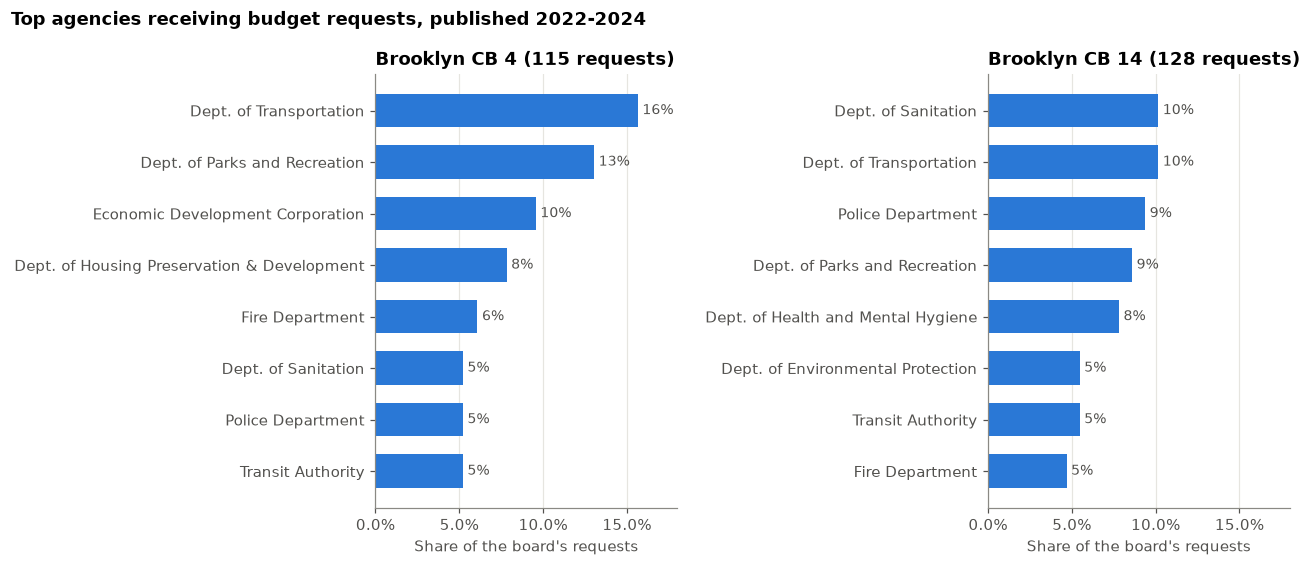

In [12]:
fig, axes = plt.subplots(1, len(BOARDS), figsize=(12, 5.2), sharex=True)
for ax, b in zip(axes, BOARDS):
    top = by_agency[by_agency["board"] == b].nlargest(8, "share")
    top = top.assign(agency=top["responsible_agency"].str.replace("Department of ", "Dept. of "))
    barh(top, "agency", "share", f"{board_label(b)} ({by_agency.loc[by_agency.board == b, 'requests'].sum():,} requests)",
         "Share of the board's requests",
         value_fmt="{:.0%}", ax=ax)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
fig.suptitle(f"Top agencies receiving budget requests, published {YEARS_LABEL}", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "requests_by_agency.png", bbox_inches="tight")
plt.show()

## 5. Do the two boards' priorities differ?

Three publication years are pooled to give the test enough requests to work with; each tracking code counts once. A chi-square test of independence checks whether the mix of agencies differs between the boards by more than chance would explain. Smaller agencies are grouped into "All other agencies" so no cell is too sparse for the test.

Three cautions shape how to read the result. First, each board files only a few dozen new requests a year, so even after pooling three years the test has limited power: a non-significant result means "no clear evidence of a difference," not "no difference." Second, Cramér's V tends to run high in small samples, so it is only interpreted when the test is significant. Third, the test assumes independent observations. Requests from one board are written together and are not truly independent, so the p-value is best read as a guide, not a precise probability.

In [13]:
# Merge the smallest agencies into "All other agencies" until every expected
# cell count is at least 5, the usual requirement for the chi-square test.
for top_n in range(TOP_AGENCIES_FOR_TEST, 0, -1):
    test_df = in_scope.assign(agency=bu.collapse_categories(in_scope["responsible_agency"], top_n))
    table = pd.crosstab(test_df["agency"], test_df["board"].map(board_label))
    res = bu.chi_square_independence(table)
    if res.min_expected >= 5:
        break

significant = res.p_value < ALPHA
strength = ("negligible" if res.cramers_v < 0.1 else "small" if res.cramers_v < 0.3
            else "moderate" if res.cramers_v < 0.5 else "large")
if significant:
    verdict = (f"The boards' agency mix differs by more than chance would explain (p < {ALPHA}); "
               f"the difference is {strength} (Cramér's V = {res.cramers_v:.2f}).")
else:
    verdict = (f"No clear evidence that the boards' agency mix differs (p = {res.p_value:.2f}). "
               f"With {len(in_scope)} requests, the test can only detect large differences, "
               "so this does not show that the boards' priorities are the same.")

print(f"Agencies kept separate: {top_n} (others merged so every expected count is at least 5)")
print(f"chi-square = {res.chi2:.1f}, df = {res.dof}, p = {res.p_value:.2g}, Cramér's V = {res.cramers_v:.2f}")
print(f"Smallest expected cell count = {res.min_expected:.1f}")
print(verdict)
table

Agencies kept separate: 6 (others merged so every expected count is at least 5)
chi-square = 8.2, df = 6, p = 0.23, Cramér's V = 0.18
Smallest expected cell count = 6.6
No clear evidence that the boards' agency mix differs (p = 0.23). With 243 requests, the test can only detect large differences, so this does not show that the boards' priorities are the same.


board,Brooklyn CB 14,Brooklyn CB 4
agency,,
All other agencies,64,55
Department of Health and Mental Hygiene,10,6
Department of Housing Preservation & Development,5,9
Department of Parks and Recreation,11,15
Department of Sanitation,13,6
Department of Transportation,13,18
Police Department,12,6


Adjusted residuals show which agencies drive the difference. Positive means the board sends **more** requests to that agency than if both boards had the same mix; values beyond about ±2 stand out.

In [14]:
res.adjusted_residuals.round(1).sort_values(res.adjusted_residuals.columns[0]).style.format("{:+.1f}")

board,Brooklyn CB 14,Brooklyn CB 4
agency,,
Department of Housing Preservation & Development,-1.3,+1.3
Department of Transportation,-1.3,+1.3
Department of Parks and Recreation,-1.1,+1.1
All other agencies,+0.3,-0.3
Department of Health and Mental Hygiene,+0.8,-0.8
Police Department,+1.2,-1.2
Department of Sanitation,+1.4,-1.4


## 6. What are the requests about?
Keywords are noun phrases (adjectives followed by nouns) pulled from each request's text. Leading instruction words such as "Provide" or "Repair" are removed, and each phrase counts once per request. Generic category labels are skipped (see Section 3.1).

In [15]:
kw_tables = {}
for b in BOARDS:
    texts = in_scope.loc[in_scope["board"] == b, "request"]
    kw_tables[b] = bu.top_keywords(texts, n=TOP_N)
    print(f"{board_label(b)}: {bu.is_generic_request(texts).sum()} of {len(texts)} requests are generic labels")

display(pd.concat({board_label(b): t.set_index("keyword")["requests"] for b, t in kw_tables.items()}, axis=1)
        .fillna(0).astype(int).sort_values(board_label(BOARDS[0]), ascending=False))

Brooklyn CB 4: 0 of 115 requests are generic labels
Brooklyn CB 14: 1 of 128 requests are generic labels


,Brooklyn CB 4,Brooklyn CB 14
keyword,,
streets,12,0
programs,7,5
existing public library,6,3
bpl,6,6
housing,6,0
park,6,0
building,6,0
transit infrastructure,6,6
upgrade subway stations,6,0


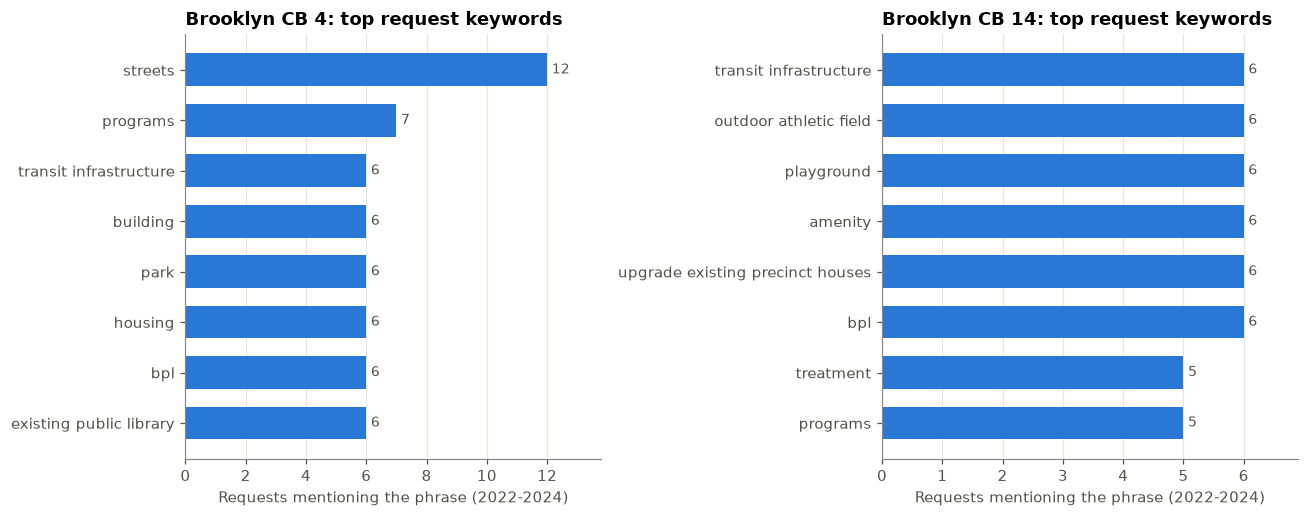

In [16]:
fig, axes = plt.subplots(1, len(BOARDS), figsize=(12, 4.8))
for ax, b in zip(axes, BOARDS):
    barh(kw_tables[b].head(8), "keyword", "requests", f"{board_label(b)}: top request keywords",
         f"Requests mentioning the phrase ({YEARS_LABEL})", ax=ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "request_keywords.png", bbox_inches="tight")
plt.show()

## 7. Citywide context: agency budgets
Totals use **one** budget publication, the latest available for the fiscal year, for the reasons shown in Section 3.2.

In [17]:
agency_budget = run_sql(conn, "expense_by_agency.sql")
agency_budget.head(TOP_N)

,agency_name,adopted_billions,modified_billions,financial_plan_billions,pct_of_citywide_modified,rank_by_modified
0,DEPARTMENT OF EDUCATION,31.565,31.938,31.032,28.00,1
1,MISCELLANEOUS,13.912,15.789,15.027,13.84,2
2,DEPARTMENT OF SOCIAL SERVICES,11.237,11.434,11.271,10.02,3
3,PENSION CONTRIBUTIONS,10.037,9.727,9.414,8.53,4
4,DEBT SERVICE,1.347,6.297,2.431,5.52,5
5,POLICE DEPARTMENT,5.437,5.881,5.531,5.16,6
6,DEPARTMENT OF HEALTH AND MENTAL HYGIENE,2.262,3.237,2.285,2.84,7
7,DEPARTMENT OF HOMELESS SERVICES,2.211,2.819,2.404,2.47,8
8,ADMIN FOR CHILDREN'S SERVICES,2.732,2.755,2.767,2.42,9
9,HEALTH AND HOSPITALS CORP,1.107,2.704,1.087,2.37,10


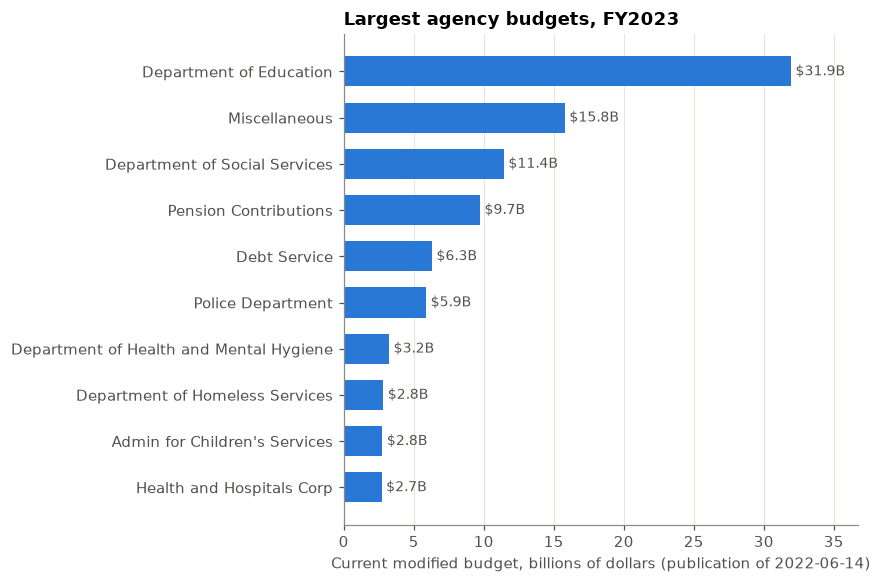

In [18]:
top_budget = agency_budget.head(TOP_N).assign(agency=lambda x: x["agency_name"].map(bu.agency_title))
barh(top_budget, "agency", "modified_billions",
     f"Largest agency budgets, FY{FISCAL_YEAR}",
     f"Current modified budget, billions of dollars (publication of {pubs['publication_date'].iloc[-1]})", value_fmt="${:,.1f}B", fname="agency_budgets.png");

## 8. Citywide context: Council discretionary funding

,category,awards,total_dollars,mean_award,pct_of_total_dollars


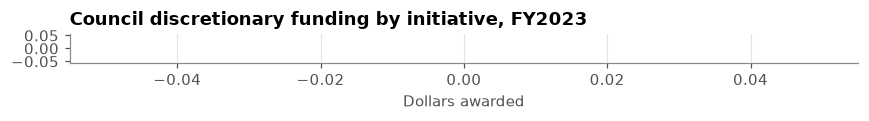

In [19]:
by_source = run_sql(conn, "discretionary_summary.sql", group_by="source")
by_org = run_sql(conn, "discretionary_summary.sql", group_by="organization")
display(by_source.head(TOP_N))
barh(by_source.head(TOP_N), "category", "total_dollars",
     f"Council discretionary funding by initiative, FY{FISCAL_YEAR}", "Dollars awarded",
     value_fmt="${:,.0f}", fname="discretionary_by_source.png");

In [20]:
by_org.head(TOP_N)

,category,awards,total_dollars,mean_award,pct_of_total_dollars


## 9. Summary
Generated from the results above, so the numbers always match the data that was loaded.

In [21]:
b1, b2 = BOARDS
def top_agencies(board):
    """All agencies tied for the largest share of a board's requests."""
    rows = by_agency[by_agency.board == board]
    top = rows[rows["share"] == rows["share"].max()]
    names = " and ".join(top["responsible_agency"])
    each = " each" if len(top) > 1 else ""
    return f"{names} ({top['share'].iloc[0]:.0%} of its requests{each})"
banner = "\n> **Fixture mode: these numbers come from synthetic test data, not NYC Open Data.**\n" if DATA_MODE != "live" else ""
display(Markdown(f"""{banner}
- **Scope.** {len(in_scope):,} distinct budget requests from {board_label(b1)} and {board_label(b2)} published in {YEARS_LABEL}.
- **Top agency for each board.** {board_label(b1)}: {top_agencies(b1)}. {board_label(b2)}: {top_agencies(b2)}.
- **Do the boards differ?** chi-square = {res.chi2:.1f} (df = {res.dof}), p = {res.p_value:.2g}. {verdict}
- **Repeated requests.** The request register repeats open requests in each publication: {n_valid:,} rows held {len(requests):,} distinct requests per year, about {n_valid / len(requests):.1f} rows per request. Counting rows instead would have inflated every count about {n_valid / len(requests):.1f}x.
- **Repeated budget publications.** Summing every publication of the FY{FISCAL_YEAR} budget would overstate totals {naive_total / latest_total:.1f}x; this analysis uses one publication.
- **Other data issues.** {int(generic.sum()):,} of {len(generic):,} downloaded rows ({generic.mean():.1%}) carry only a generic category label as their request text.
- **Citywide context.** The largest FY{FISCAL_YEAR} agency budget is {bu.agency_title(agency_budget.iloc[0].agency_name)} at ${agency_budget.iloc[0].modified_billions:,.1f}B ({agency_budget.iloc[0].pct_of_citywide_modified:.1f}% of the total).
"""))


- **Scope.** 243 distinct budget requests from Brooklyn CB 4 and Brooklyn CB 14 published in 2022-2024.
- **Top agency for each board.** Brooklyn CB 4: Department of Transportation (16% of its requests). Brooklyn CB 14: Department of Transportation and Department of Sanitation (10% of its requests each).
- **Do the boards differ?** chi-square = 8.2 (df = 6), p = 0.23. No clear evidence that the boards' agency mix differs (p = 0.23). With 243 requests, the test can only detect large differences, so this does not show that the boards' priorities are the same.
- **Repeated requests.** The request register repeats open requests in each publication: 27,754 rows held 10,083 distinct requests per year, about 2.8 rows per request. Counting rows instead would have inflated every count about 2.8x.
- **Repeated budget publications.** Summing every publication of the FY2023 budget would overstate totals 2.9x; this analysis uses one publication.
- **Other data issues.** 120 of 29,018 downloaded rows (0.4%) carry only a generic category label as their request text.
- **Citywide context.** The largest FY2023 agency budget is Department of Education at $31.9B (28.0% of the total).


## 10. Limitations

- **Requests are not spending.** The register records what boards asked for and the agency's response, not what was funded. Counting requests measures the boards' priorities, not dollars delivered.
- **Request counts depend on how boards write them.** One board may bundle needs into a single request while another splits them up, which affects agency shares and the chi-square test.
- **Re-filed requests.** In this data, tracking codes do not repeat across years (Section 3.1 shows how many carried over). A need that a board submits again each year under a new code therefore counts once per year in the pooled comparison, which gives long-standing needs more weight.
- **Pooled years.** Combining three years assumes each board's priorities were roughly stable over that time. A shift within the window would be averaged out.
- **Borough coding.** This dataset's borough codes appear to be alphabetical (Brooklyn is 2), unlike many City datasets where Brooklyn is 3. The notebook checks that the download has the expected number of community boards before going on.
- **Generic category labels hide content.** Requests labeled only "Other ... budget request" carry an agency but no topic, so the keyword analysis understates whatever they would have described.
- **Keyword extraction is rule-based.** Part-of-speech tagging can mislabel words in short, list-like request text (for example, "home delivered meals" can be split). Keywords are a way to explore the text, not a classification.
- **Budget publication choice.** Agency totals use the latest publication in the dataset for the fiscal year. A different publication (for example, the adopted budget) gives somewhat different figures. Section 3.2 shows all of them.
- **No geographic link for citywide budgets.** The expense budget and discretionary funding data in this notebook are not broken out by community board, so they provide context and cannot be compared one-to-one with the boards' requests.